In [1]:
import pandas as pd
import scipy.stats
import umap
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
import torch
import os
import sys
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))
from matplotlib.ticker import MaxNLocator
from BWM.bwm_functions import *
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [2]:
# Set directory path and select an EID
directory_path = '../Data2'
all_items = os.listdir(directory_path)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]


In [3]:
# Data loading using get_region_response_matrix
region = 'CP' # Caudoputamen
pseudo_response_tensor, condition_matrix, neuron_eids = get_region_response_matrix(
    eids=eids,
    directory_path=directory_path,
    region=region,
    mapping='Beryl',
    sigma=5,
    n_steps=100,
    threshold=5,
    min_trials_per_condition=50,
    n_pseudo=25,
    conditions=['choice'],
    event="stimOn_times",
    filter_significant=True,
    significance_threshold=0.6
)




Aggregating CP responses across 459 EIDs...


Dispatching jobs:   7%|▋         | 32/459 [00:12<03:18,  2.15it/s]/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Dispatching jobs: 100%|██████████| 459/459 [03:17<00:00,  2.33it/s]


Max conditions: 2, Common conditions found: [(np.float64(-1.0),), (np.float64(1.0),)]
Total neurons collected: 4932


In [4]:

def iso_ae_preprocessing(pseudo_response_tensor):
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])

    X_transposed = response_matrix.T

    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)

    # Reduce features to 20 using PCA

    return X_pre_pca

X = iso_ae_preprocessing(pseudo_response_tensor)

In [13]:
def calculate_msd(response_matrix):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    # Assuming 2 conditions and 100 time points as in the preprocessing
    # response_matrix shape is (neurons, conditions * time)
    # We need to reshape it back to (neurons, conditions, time)
    n_neurons = response_matrix.shape[0]
    n_conditions = 2 # From get_region_response_matrix conditions=['choice']
    n_time = 100
    
    response_matrix_expand = response_matrix.reshape(n_neurons, n_conditions, n_time)
    diff_responses = np.diff(response_matrix_expand, axis=2)
    # Mean over conditions and time
    msd = np.mean(np.abs(diff_responses), axis=(1, 2))
    return msd

msd = calculate_msd(X)

# Select a neuron in the top 25% of MSD values
top_25_percentile = np.percentile(msd, 75)
potential_indices = np.where(msd >= top_25_percentile)[0]
# Pick one neuron consistently - e.g., the one with the highest MSD or just a fixed one from the list
chosen_neuron_idx = potential_indices[len(potential_indices) // 2] 

# Find 10 nearest neighbors in original space X
from sklearn.neighbors import NearestNeighbors
k_nn = 50
nn = NearestNeighbors(n_neighbors=k_nn + 1).fit(X)
distances, nn_indices = nn.kneighbors(X[chosen_neuron_idx].reshape(1, -1))
nn_indices = nn_indices[0][1:] # Exclude the neuron itself

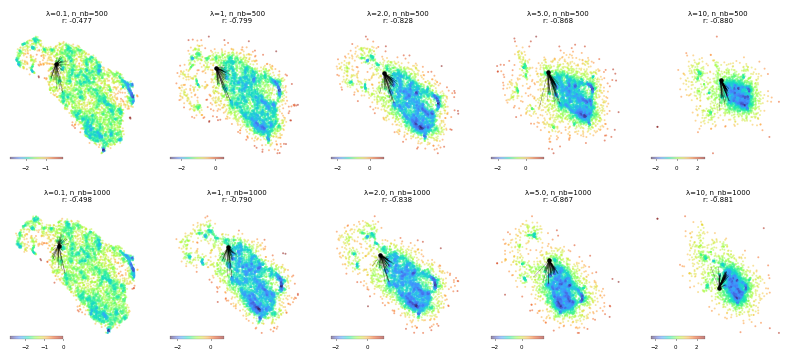

In [28]:
import umap
from scipy.stats import pearsonr

# Hyperparameters grid
dens_lambdas = [0.1,1,2.0,5.0,10]
n_neighbors_list = [ 500,1000]

n_rows = len(n_neighbors_list)
n_cols = len(dens_lambdas)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(2 * n_cols, 2 * n_rows))
plt.subplots_adjust(hspace=0.4, wspace=0.2)

# Original data density proxy (inverse of average k-NN distance)
# Using k=50 as seen in other notebooks
k_neighbors = 50
original_density_proxy = get_density_proxy(X, k=k_neighbors).numpy()

# We want density, not inverse density (distance), so we take 1/dist
# But correlation is what matters, so we can use -dist or 1/dist. 
# The issue says "correlation between msd and density", 
# and "correlation between density in original space and densMAP projections".
# DensMAP's output_dens=True returns log density.

original_log_density = -np.log(original_density_proxy + 1e-8)

for i, n_neighbors in enumerate(n_neighbors_list):
    for j, dens_lambda in enumerate(dens_lambdas):
        ax = axes[i, j]
        
        # Fit densMAP
        reducer = umap.UMAP(
            densmap=True, 
            dens_lambda=dens_lambda, 
            n_neighbors=n_neighbors, 
            output_dens=True,
        )
        embedding, dens_orig, dens_emb = reducer.fit_transform(X)
        
        # dens_orig and dens_emb are log densities from densMAP
        
        # Calculate correlations
        corr_orig_emb, _ = pearsonr(original_log_density, dens_emb)
        
        # Plot
        sc = ax.scatter(embedding[:, 0], embedding[:, 1], c=dens_emb, cmap='turbo', s=2, alpha=0.5,lw = 0)
        
        # Highlight chosen neuron and its neighbors
        ax.scatter(embedding[chosen_neuron_idx, 0], embedding[chosen_neuron_idx, 1], 
                   color='black', s=5, zorder=5)
        # ax.scatter(embedding[nn_indices, 0], embedding[nn_indices, 1],
        #            color='black', s=1, zorder=5)
        
        # Draw lines between neuron and its neighbors
        for nn_idx in nn_indices:
            ax.plot([embedding[chosen_neuron_idx, 0], embedding[nn_idx, 0]], 
                    [embedding[chosen_neuron_idx, 1], embedding[nn_idx, 1]], 
                    color='black', linewidth=0.2, alpha=0.8, zorder=4)

        ax.set_title(f"λ={dens_lambda}, n_nb={n_neighbors}\n"
                     f"r: {corr_orig_emb:.3f}",
                     fontsize=5)
        ax.axis('off')
        
        # Add individual colorbar for density
        from mpl_toolkits.axes_grid1.inset_locator import inset_axes
        cax_dens = inset_axes(ax, width="40%", height="2%", loc="lower left", borderpad=0)
        cb = fig.colorbar(sc, cax=cax_dens, orientation="horizontal")
        cb.outline.set_linewidth(0.1)
        cax_dens.xaxis.set_tick_params(size=1, width=.5, color="black", labelsize=4)

plt.savefig('densmap_hyperparameters_grid.png', dpi=300, bbox_inches='tight')
plt.show()
